# Econ 3916 PS4 — The Model That Fit Too Well

**ECON 3916 · Applied Data Analytics** · Topics 12-15 · 100 points · your role: Analyst, Revenue Forecasting

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is analyst's audience, not a grader with a kernel.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

## Phase 1: Reproduce the 0.94 (30 pts)

### Step 1.1: Build the store panel (10 pts)

In [2]:
import statsmodels.api as sm

# What the brief fixes (Step 1.1). Keep it here so the grader can rerun you.
N_STORES = 400               # at least 400 stores
# predictors: floor area, foot traffic, local median income, years open,
# several that are irrelevant, and one that is nearly a linear combination of two others

In [3]:
floor_area = rng.uniform(8, 45, N_STORES)
foot_traffic = 1.5 * floor_area + rng.uniform(5, 30, N_STORES)
median_income = rng.normal(65, 15, N_STORES)
years_open = rng.integers(1, 30, N_STORES)
staff = 0.8 * floor_area + 0.25 * foot_traffic + rng.normal(0, 1, N_STORES)
manager_age = rng.integers(25, 65, N_STORES)
rainfall_mm = rng.normal(90, 25, N_STORES)
warehouse_km = rng.uniform(5, 200, N_STORES)
parking_spaces = rng.integers(20, 200, N_STORES)
lease_years = rng.integers(1, 20, N_STORES)
wifi_mbps = rng.normal(100, 30, N_STORES)
door_count = rng.integers(1, 5, N_STORES)

big = floor_area > 34
flat_part = 34 + 0.2 * (floor_area - 34)
area_effect = np.where(big, flat_part, floor_area)
true_revenue = 20 + 10 * area_effect + 0.5 * foot_traffic + 0.8 * median_income + 1.5 * years_open
noise_sd = 0.6 * floor_area
revenue = true_revenue + rng.normal(0, noise_sd, N_STORES)

stores = pd.DataFrame({
    "floor_area": floor_area,
    "foot_traffic": foot_traffic,
    "median_income": median_income,
    "years_open": years_open,
    "staff": staff,
    "manager_age": manager_age,
    "rainfall_mm": rainfall_mm,
    "warehouse_km": warehouse_km,
    "parking_spaces": parking_spaces,
    "lease_years": lease_years,
    "wifi_mbps": wifi_mbps,
    "door_count": door_count,
    "revenue": revenue,
})
X = stores.drop(columns="revenue")
y = stores["revenue"]
print(stores.describe().round(1))

       floor_area  foot_traffic  median_income  years_open  staff  \
count       400.0         400.0          400.0       400.0  400.0   
mean         26.4          56.9           65.1        15.0   35.2   
std          10.5          17.5           14.7         8.6   12.6   
min           8.3          18.4           10.3         1.0   10.2   
25%          16.9          43.0           56.5         7.0   24.2   
50%          26.2          57.6           65.5        14.0   35.5   
75%          36.1          70.0           74.0        23.0   45.7   
max          44.7          93.5          112.7        29.0   59.4   

       manager_age  rainfall_mm  warehouse_km  parking_spaces  lease_years  \
count        400.0        400.0         400.0           400.0        400.0   
mean          44.6         90.9         105.7           108.9          9.4   
std           11.5         24.8          55.4            50.9          5.6   
min           25.0         13.4           5.5            20.0     

*The data-generating process, recorded: every predictor and the true revenue equation.*

revenue (thousand dollars a month) = 20 + 10 × area_effect + 0.5 × foot_traffic + 0.8 × median_income + 1.5 × years_open + Normal(0, 0.6 × floor_area)

- area_effect = floor_area up to 34 and 34 + 0.2 × (floor_area - 34) above that so the biggest stores grow more slowly
- floor_area = Uniform(8, 45) and foot_traffic = 1.5 × floor_area + Uniform(5, 30)
- median_income = Normal(65, 15) and years_open = a whole number from 1 to 29
- staff = 0.8 × floor_area + 0.25 × foot_traffic + Normal(0, 1) so it's nearly a linear combination of the two
- true effect of 0 for staff, manager_age (25 to 64), rainfall_mm Normal(90, 25), warehouse_km Uniform(5, 200), parking_spaces (20 to 199), lease_years (1 to 19), wifi_mbps Normal(100, 30) and door_count (1 to 4)

### Step 1.2: Fit it the way they did (12 pts)

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_STATE = 42

full_fit = sm.OLS(y, sm.add_constant(X)).fit()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
split_fit = LinearRegression().fit(X_train, y_train)
train_pred = split_fit.predict(X_train)
test_pred = split_fit.predict(X_test)
train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, test_pred)
gap = train_r2 - test_r2

print(f"R-squared, all 400 stores:      {full_fit.rsquared:.3f}")
print(f"R-squared, 320 training stores: {train_r2:.3f}")
print(f"R-squared, 80 held-out stores:  {test_r2:.3f}")
print(f"Gap (training - held-out):      {gap:.3f}")

R-squared, all 400 stores:      0.943
R-squared, 320 training stores: 0.945
R-squared, 80 held-out stores:  0.934
Gap (training - held-out):      0.011


*Your answer here.*

R-squared is 0.943 on all 400 stores and after splitting and refitting it's 0.945 on the 320 training stores and 0.934 on the 80 held-out stores so the gap is 0.011.

### Step 1.3: Say what R-squared is (8 pts)

In [5]:
X_noise = X.copy()
X_noise["noise_1"] = rng.normal(0, 1, N_STORES)
X_noise["noise_2"] = rng.normal(0, 1, N_STORES)
X_noise["noise_3"] = rng.normal(0, 1, N_STORES)
noise_fit = sm.OLS(y, sm.add_constant(X_noise)).fit()

print(f"R-squared:          {full_fit.rsquared:.4f} -> {noise_fit.rsquared:.4f}")
print(f"Adjusted R-squared: {full_fit.rsquared_adj:.4f} -> {noise_fit.rsquared_adj:.4f}")

R-squared:          0.9433 -> 0.9435
Adjusted R-squared: 0.9416 -> 0.9413


*Your answer here.*

R-squared can't go down because OLS can always set a new coefficient to zero and keep the old fit so choosing by R-squared always picks the model with the most predictors even when they're noise, and adding three noise columns moved R-squared up from 0.9433 to 0.9435 and adjusted R-squared down from 0.9416 to 0.9413.

## Phase 2: Diagnose the Failure (35 pts)

### Step 2.1: Look at the residuals (20 pts)

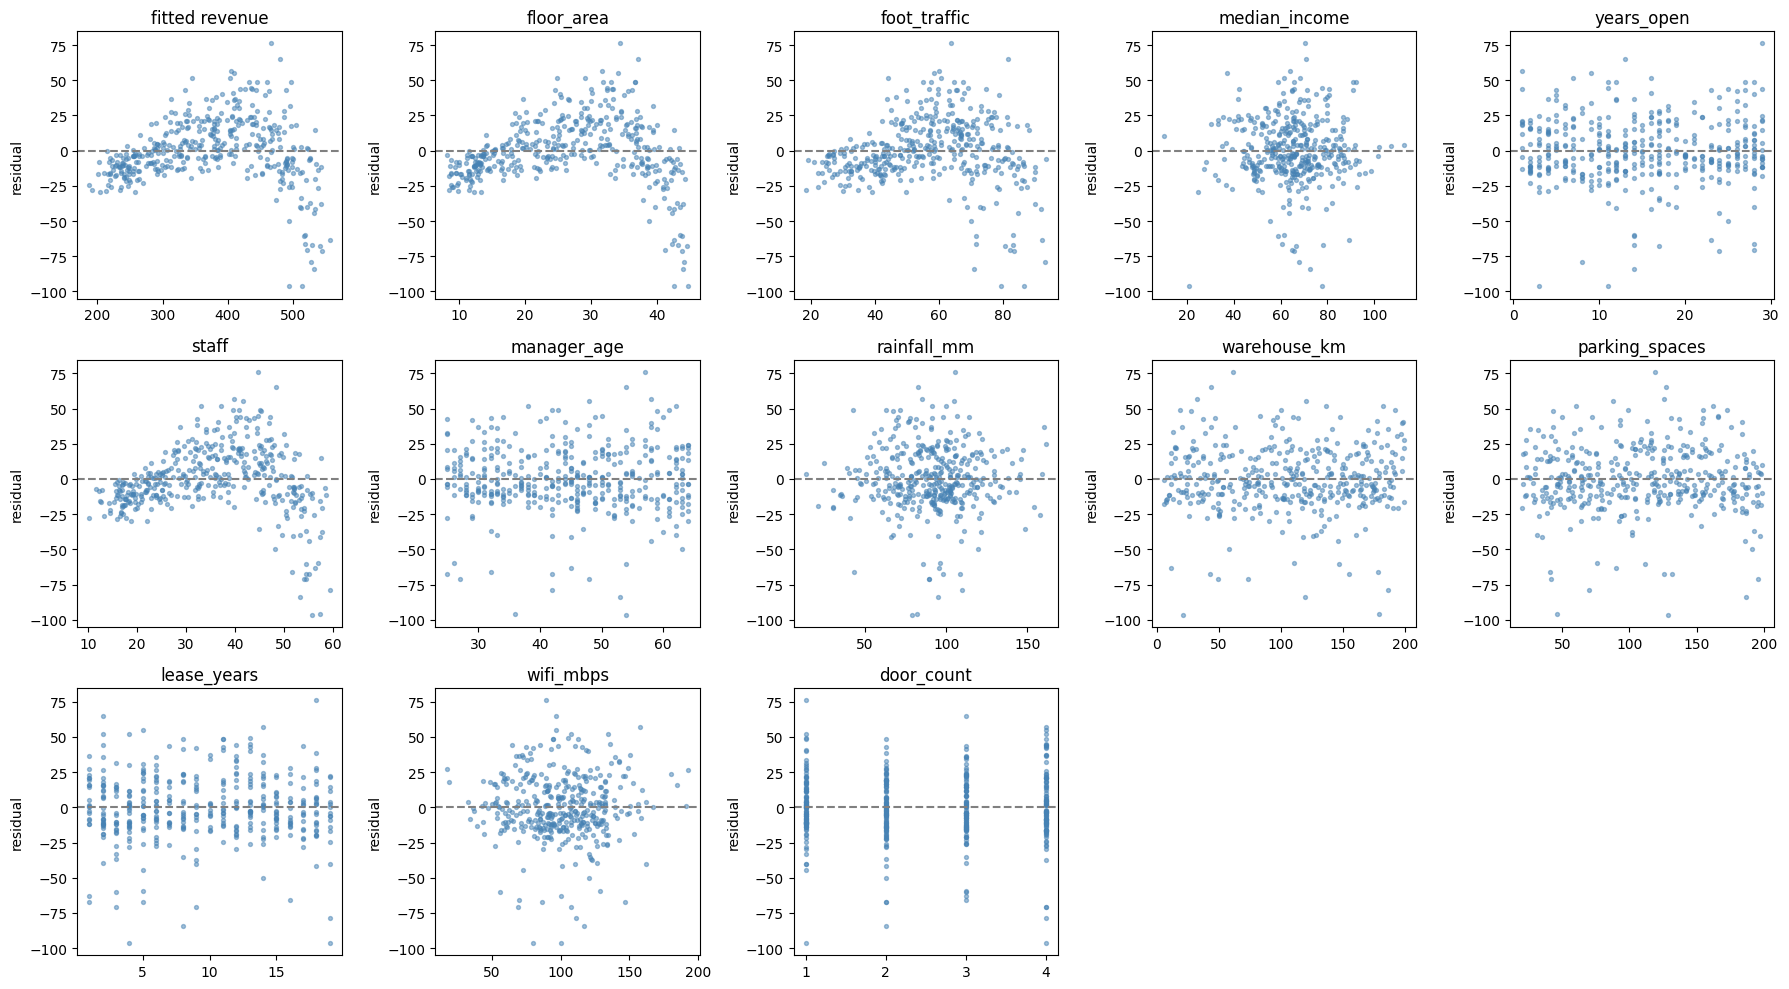

Breusch-Pagan p-value: 0.0000


In [6]:
from statsmodels.stats.diagnostic import het_breuschpagan

fig, axes = plt.subplots(3, 5, figsize=(18, 10))
axes = axes.flatten()
axes[0].scatter(full_fit.fittedvalues, full_fit.resid, s=8, alpha=0.5, color="steelblue")
axes[0].set_title("fitted revenue")
for ax, col in zip(axes[1:13], X.columns):
    ax.scatter(X[col], full_fit.resid, s=8, alpha=0.5, color="steelblue")
    ax.set_title(col)
for ax in axes[:13]:
    ax.axhline(0, color="gray", linestyle="--")
    ax.set_ylabel("residual")
axes[13].axis("off")
axes[14].axis("off")
plt.tight_layout()
plt.show()

bp_p = het_breuschpagan(full_fit.resid, full_fit.model.exog)[1]
print(f"Breusch-Pagan p-value: {bp_p:.4f}")

*Your answer here.*

1. Non-constant variance shows up as residuals that fan out as floor_area goes up (Breusch-Pagan p = 0.0000) and it violates constant variance which leaves the estimate unbiased but makes the standard error wrong.
2. A missed curve shows up as residuals that arch below zero for the smallest and biggest stores and it violates the right functional form which makes both the estimate and the standard error wrong.

### Step 2.2: The over-forecast on big stores (15 pts)

In [7]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

yv = y.values
area = X["floor_area"].values
order = np.argsort(area)
over = full_fit.fittedvalues.values - yv
print("size fifth  floor area      over % of rev")
for group in range(1, 6):
    start = (group - 1) * 80
    stop = group * 80
    idx = order[start:stop]
    area_mean = area[idx].mean()
    over_mean = over[idx].mean()
    share = over_mean / yv[idx].mean()
    print(f"{group:<12}{area_mean:>10.1f}{over_mean:>10.1f}{share:>9.1%}")
top_over = over[order[320:]]
t_top = top_over.mean() / (np.std(top_over, ddof=1) / np.sqrt(len(top_over)))
print(f"Biggest fifth t-statistic: {t_top:.2f}")

X_const = sm.add_constant(X)
Xv = X_const.values
print("predictor            VIF")
for i, name in enumerate(X_const.columns):
    if name != "const":
        print(f"{name:<16}{variance_inflation_factor(Xv, i):>8.1f}")

X_no_staff = X.drop(columns="staff")
no_staff = sm.OLS(y, sm.add_constant(X_no_staff)).fit()
over_no_staff = no_staff.fittedvalues.values - yv
se_with = full_fit.bse["floor_area"]
se_without = no_staff.bse["floor_area"]
over_with = top_over.mean()
over_without = over_no_staff[order[320:]].mean()
print(f"SE on floor_area: {se_with:.3f} with staff, {se_without:.3f} without")
print(f"R-squared: {full_fit.rsquared:.4f} with staff, {no_staff.rsquared:.4f} without")
print(f"Biggest fifth over-forecast: {over_with:.1f} with staff, {over_without:.1f} without")

size fifth  floor area      over % of rev
1                 11.8      12.3     5.4%
2                 18.9      -2.2    -0.7%
3                 26.5     -12.2    -3.2%
4                 33.9     -17.6    -3.9%
5                 40.8      19.6     4.1%
Biggest fifth t-statistic: 5.93
predictor            VIF
floor_area          74.5
foot_traffic        24.2
median_income        1.0
years_open           1.0
staff              153.1
manager_age          1.0
rainfall_mm          1.0
warehouse_km         1.0
parking_spaces       1.0
lease_years          1.0
wifi_mbps            1.0
door_count           1.0
SE on floor_area: 0.977 with staff, 0.270 without
R-squared: 0.9433 with staff, 0.9433 without
Biggest fifth over-forecast: 19.6 with staff, 19.7 without


*Your answer here.*

The error is systematic because the model over-forecasts the biggest fifth of stores by \$19,600 a month (4.1% of their revenue, t = 5.93) and under-forecasts the middle stores. The VIF is 153.1 for staff, 74.5 for floor_area, 24.2 for foot_traffic and 1.0 for the rest, and high VIF makes those standard errors bigger (floor_area's goes from 0.270 to 0.977) but doesn't bias the estimates or hurt predictions so dropping staff leaves R-squared at 0.9433 and the big-store over-forecast at \$19,600.

## Phase 3: Build Something Honest (25 pts)

### Step 3.1: The complexity sweep (14 pts)

model                    terms  training  held-out
floor area                   1     28.64     28.93
+ foot traffic               2     28.51     28.60
+ income, years open         4     23.33     25.51
+ floor area^2               5     18.03     19.17
+ floor area^3               6     16.41     18.32
+ other 8 predictors        14     16.28     18.51
+ all squares               25     16.10     18.83
+ all interactions          91     13.85     19.35


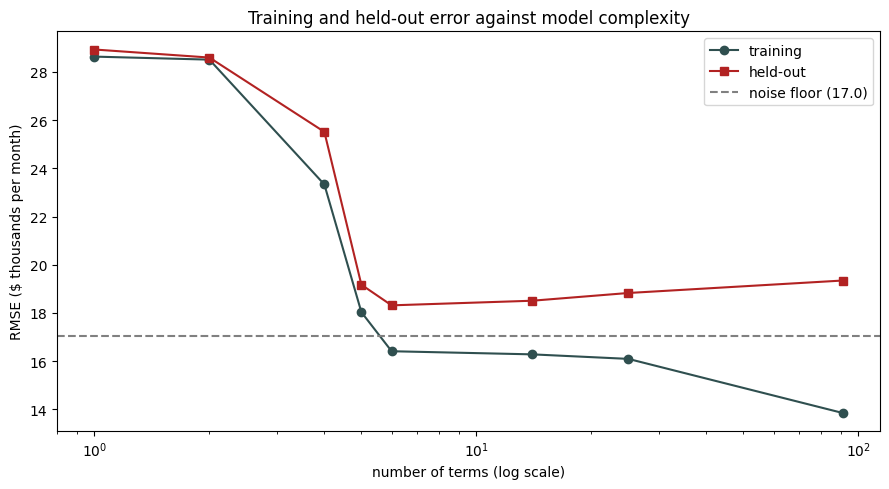

In [8]:
Xa = X.values
feats = [Xa[:, 0], Xa[:, 1], Xa[:, 2], Xa[:, 3], Xa[:, 0] ** 2, Xa[:, 0] ** 3]
for j in range(4, 12):
    column = Xa[:, j]
    feats.append(column)
for j in range(1, 12):
    feats.append(Xa[:, j] ** 2)
for i in range(12):
    for j in range(i + 1, 12):
        feats.append(Xa[:, i] * Xa[:, j])

names = ["floor area", "+ foot traffic", "+ income, years open", "+ floor area^2", "+ floor area^3",
         "+ other 8 predictors", "+ all squares", "+ all interactions"]
n_terms = [1, 2, 4, 5, 6, 14, 25, 91]

train_rmse, test_rmse = [], []
print("model                    terms  training  held-out")
for name, k in zip(names, n_terms):
    cols_k = feats[:k]
    Pk = np.column_stack(cols_k)
    P_train, P_test, y_train, y_test = train_test_split(Pk, y, test_size=0.2, random_state=RANDOM_STATE)
    fit = LinearRegression().fit(P_train, y_train)
    tr_rmse = np.sqrt(mean_squared_error(y_train, fit.predict(P_train)))
    te_rmse = np.sqrt(mean_squared_error(y_test, fit.predict(P_test)))
    train_rmse.append(tr_rmse)
    test_rmse.append(te_rmse)
    print(f"{name:<24}{k:>6}{tr_rmse:>10.2f}{te_rmse:>10.2f}")

noise_floor = np.sqrt(np.mean(noise_sd ** 2))
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(n_terms, train_rmse, "o-", label="training", color="darkslategray")
ax.plot(n_terms, test_rmse, "s-", label="held-out", color="firebrick")
ax.axhline(noise_floor, color="gray", linestyle="--", label=f"noise floor ({noise_floor:.1f})")
ax.set_xscale("log")
ax.set_xlabel("number of terms (log scale)")
ax.set_ylabel("RMSE ($ thousands per month)")
ax.set_title("Training and held-out error against model complexity")
ax.legend()
plt.tight_layout()
plt.show()

*Your answer here.*

Held-out error turns at 6 terms where floor area squared and cubed are added and it's lowest at \$18,320, and the falling half is underfitting where the error is mostly bias and the rising half is overfitting where the error is mostly variance.

### Step 3.2: Choose, and be honest about the estimate (11 pts)

In [9]:
from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def cv_errors(Xm, ym):
    """Out-of-fold errors of OLS on Xm and ym with 5-fold CV."""
    errs = []
    for tr_i, te_i in kf.split(Xm):
        fit = LinearRegression().fit(Xm[tr_i], ym[tr_i])
        fold_err = fit.predict(Xm[te_i]) - ym[te_i]
        errs.append(fold_err)
    return np.array(errs).flatten()


cv_rmse = []
for name, k in zip(names, n_terms):
    cols_k = feats[:k]
    errs_k = cv_errors(np.column_stack(cols_k), yv)
    k_rmse = np.sqrt(np.mean(errs_k ** 2))
    cv_rmse.append(k_rmse)
    print(f"{name:<24}{k_rmse:>10.2f}")
best = int(np.argmin(cv_rmse))
k_cv = n_terms[best]
cols_best = feats[:k_cv]
sq_err = cv_errors(np.column_stack(cols_best), yv) ** 2
res = stats.bootstrap((sq_err,), np.mean, confidence_level=0.95, random_state=rng)
lo, hi = res.confidence_interval
cv_lo = np.sqrt(lo)
cv_hi = np.sqrt(hi)
print(f"Chosen by CV: {names[best]}, RMSE {cv_rmse[best]:.2f}, 95% CI [{cv_lo:.2f}, {cv_hi:.2f}]")

outer_err, picked = [], []
for tr_i, te_i in kf.split(Xa):
    inner = []
    for k in n_terms:
        cols_k = feats[:k]
        Pk = np.column_stack(cols_k)
        inner_err = cv_errors(Pk[tr_i], yv[tr_i])
        inner.append(np.mean(inner_err ** 2))
    k_best = n_terms[int(np.argmin(inner))]
    picked.append(k_best)
    cols_k = feats[:k_best]
    Pk = np.column_stack(cols_k)
    fit = LinearRegression().fit(Pk[tr_i], yv[tr_i])
    fold_err = fit.predict(Pk[te_i]) - yv[te_i]
    outer_err.append(fold_err)
sq_outer = np.array(outer_err).flatten() ** 2
res = stats.bootstrap((sq_outer,), np.mean, confidence_level=0.95, random_state=rng)
lo, hi = res.confidence_interval
nested_rmse = np.sqrt(np.mean(sq_outer))
nested_lo = np.sqrt(lo)
nested_hi = np.sqrt(hi)
print(f"Nested CV: RMSE {nested_rmse:.2f}, 95% CI [{nested_lo:.2f}, {nested_hi:.2f}]")
print(f"Terms picked in each outer fold: {picked}")
print(f"Noise floor from the true process: {noise_floor:.2f}")

floor area                   28.84
+ foot traffic               28.78
+ income, years open         24.35
+ floor area^2               18.74
+ floor area^3               17.21
+ other 8 predictors         17.70
+ all squares                18.30
+ all interactions           20.78
Chosen by CV: + floor area^3, RMSE 17.21, 95% CI [15.84, 18.93]
Nested CV: RMSE 17.21, 95% CI [15.82, 18.88]
Terms picked in each outer fold: [6, 6, 6, 6, 6]
Noise floor from the true process: 17.04


*Your answer here.*

5-fold CV picks the 6-term model with an expected RMSE of \$17,210 a month (95% CI \$15,840 to \$18,930) but picking the lowest of eight CV errors favors the model that got lucky on these folds so that number is too low on average. Nested CV fixes this by choosing the model inside each outer fold and gives \$17,210 (95% CI \$15,820 to \$18,880) which is the same because every fold picked the same model.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The learning curve (4 pts)

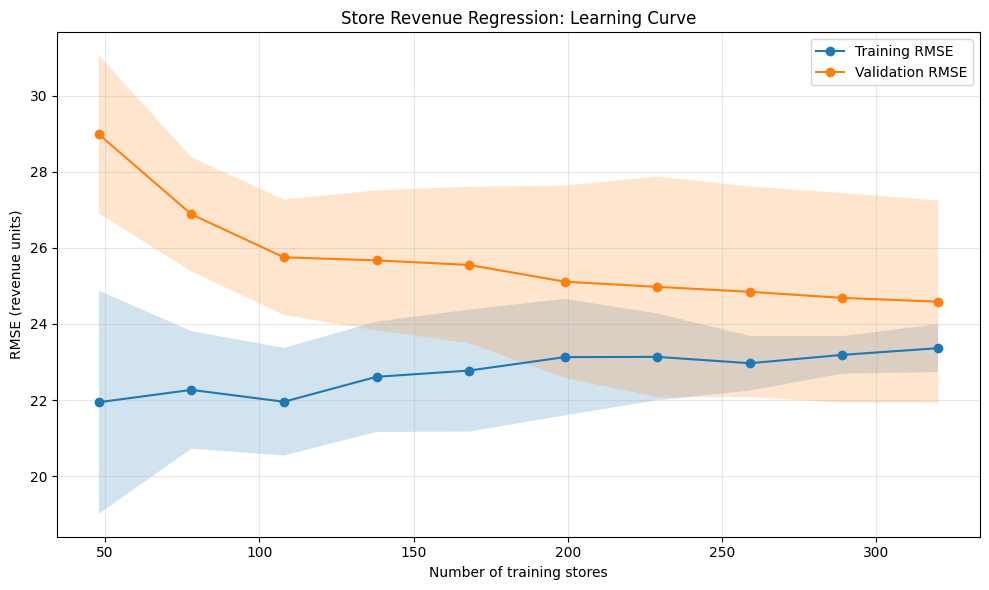

Training RMSE: 23.36
Validation RMSE: 24.59
Baseline RMSE: 98.60
Generalization gap: 1.22
Relative gap: 5.0%
Recent validation improvement: 1.0%
No clear high-bias or high-variance diagnosis.
Compare against business error targets before investing.


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, learning_curve, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor

# Reuse the existing X (predictors) and y (store revenue).
# Replace this pipeline with your production model if different.
model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))

# Five shuffled folds for reproducible evaluation.
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate training sizes from 15% to 100% of each training fold.
sizes, train_scores, val_scores = learning_curve(
    estimator=model,
    X=X,
    y=y,
    train_sizes=np.linspace(0.15, 1.0, 10),
    cv=cv,
    scoring="neg_root_mean_squared_error",
    shuffle=True,
    random_state=42,
    n_jobs=-1
)

# sklearn returns negative RMSE because higher scores are better.
train_errors = -train_scores
val_errors = -val_scores

train_mean = train_errors.mean(axis=1)
val_mean = val_errors.mean(axis=1)

train_std = train_errors.std(axis=1)
val_std = val_errors.std(axis=1)

# Plot both learning curves.
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(sizes, train_mean, "o-", label="Training RMSE")
ax.plot(sizes, val_mean, "o-", label="Validation RMSE")

# Shaded bands show variability across the five folds.
ax.fill_between(
    sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.2
)

ax.fill_between(
    sizes,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.2
)

ax.set_xlabel("Number of training stores")
ax.set_ylabel("RMSE (revenue units)")
ax.set_title("Store Revenue Regression: Learning Curve")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Compare against predicting the mean revenue for every store.
baseline_scores = cross_val_score(
    DummyRegressor(strategy="mean"),
    X, y, cv=cv,
    scoring="neg_root_mean_squared_error"
)
baseline_rmse = -baseline_scores.mean()

# GAP: A large validation-training gap suggests high variance.
# The model fits training stores better than unseen stores.
# More representative stores may reduce this gap.

# LEVEL: If both curves converge at high error, bias or noise
# may be limiting performance. More stores alone may not help.
# Better predictors or a more flexible model may help instead.

gap = val_mean[-1] - train_mean[-1]
gap_ratio = gap / max(val_mean[-1], 1e-12)
improvement = (
    (val_mean[-3] - val_mean[-1])
    / max(val_mean[-3], 1e-12)
)

print(f"Training RMSE: {train_mean[-1]:.2f}")
print(f"Validation RMSE: {val_mean[-1]:.2f}")
print(f"Baseline RMSE: {baseline_rmse:.2f}")
print(f"Generalization gap: {gap:.2f}")
print(f"Relative gap: {gap_ratio:.1%}")
print(f"Recent validation improvement: {improvement:.1%}")

# Illustrative thresholds, not definitive statistical tests.
if gap_ratio > 0.20:
    if improvement > 0.03:
        print("Likely high variance: more stores may help.")
    else:
        print("Possible high variance, but improvement is flattening.")
        print("Test stronger regularization before buying more data.")

elif val_mean[-1] >= 0.80 * baseline_rmse:
    print("Possible high bias or limited predictive signal.")
    print("Prioritize better features or a more flexible model.")

else:
    print("No clear high-bias or high-variance diagnosis.")
    print("Compare against business error targets before investing.")

*Your answer here.*

It doesn't agree because ChatGPT's code only flags high bias when validation RMSE is close to the \$98,600 from just guessing average revenue, but Phase 3 is right because the curves end only \$1,220 apart at \$24,590 far above the \$17,040 noise floor and adding the floor area curve cut CV RMSE to \$17,210, so the model has high bias and I'd invest in better features instead of more stores.

### Task 4.2: What "validated" meant (3 pts)

> **No AI on this task, and no transcript.** Here you are the reviewer.

The departing analyst's cell, copied from the brief. For (b), run it as it is with 300 pure-noise columns alone as `X` and your Phase 1 revenue as `y`.

In [11]:
X = rng.normal(0, 1, (N_STORES, 300))

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2: {scores.mean():.2f}")

Validated R^2: 0.08


In [13]:
from sklearn.pipeline import make_pipeline

folds = KFold(n_splits=5)
fold_r2 = []
for train_idx, test_idx in folds.split(X):
    model = make_pipeline(StandardScaler(), SelectKBest(f_regression, k=20), LinearRegression())
    model.fit(X[train_idx], yv[train_idx])
    predictions = model.predict(X[test_idx])
    y_fold = yv[test_idx]
    fold_r2.append(r2_score(y_fold, predictions))

leaked_r2 = scores.mean()
honest_r2 = np.mean(fold_r2)
gap_42 = leaked_r2 - honest_r2
print(f"Analyst's cell:     {leaked_r2:.2f}")
print(f"Inside a pipeline:  {honest_r2:.2f}")
print(f"Gap:                {gap_42:.2f}")

Analyst's cell:     0.08
Inside a pipeline:  -0.28
Gap:                0.36


*Your answer here.*

(a) SelectKBest inflates the score because it picks its 20 columns using revenue from the test folds too and StandardScaler is harmless because OLS with an intercept undoes any shift or rescale so the predictions don't change.

(b) The analyst's cell prints 0.08 and the same steps inside a pipeline give -0.28 so the gap is 0.36.

(c) It's a special case because both make a choice with the same stores that score the model, and here the choice even saw the test stores' revenue.

### Task 4.3: The handover note (3 pts)

*Your answer here.*

This model predicts each store's monthly revenue from floor area, foot traffic, local median income and years open, and it adds floor area squared and cubed so revenue can grow more slowly for the biggest stores. Its honest expected error is about \$17,200 a month (95% CI \$15,800 to \$18,900) from nested 5-fold CV, which is about 5% of the average store's \$373,000 a month.

It will fail in two cases, first for the biggest stores because their revenue is more spread out so their forecasts miss by more than the average error, and second for any store outside 8,000 to 45,000 square feet or with a new store format because the curve can bend the wrong way outside the sizes it learned from.

Next I'd build a version that gives each store its own error range that grows with store size, and I'd look for new predictors like local competition instead of collecting more stores because the learning curve shows more stores won't lower the error much. I'd also check the error every month on new data the model hasn't seen so the stated error stays honest.

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

*Model and date:* Chatgpt Nov 18 2026

*Prompt:*
```
[Prep] Act as a machine learning engineer who diagnoses model
performance problems in production.

[Request] I have a store-level revenue regression with 400 rows and
about 12 predictors. Write Python that produces a learning curve --
training and validation error as a function of training set size --
and interprets it to distinguish a high-bias problem from a
high-variance one.

[Iterate] scikit-learn, numpy and matplotlib. Reuse my X and y. Plot
both curves on one axis with a shaded band for variability across
folds.

[Mechanism Check] Add comments explaining what the GAP between the two
curves indicates versus what the LEVEL both converge to indicates, and
what each implies about whether collecting more data would help.

[Evaluate] Run it on my data and tell me whether more stores or better
features is the higher-return investment.
```
*Reply:*

This uses 5-fold cross-validation to show how training and validation errors change as the number of stores increases. It also compares your regression against a simple baseline to help distinguish high bias from high variance.

The code uses your existing `X` and `y`, with no simulated data.

## Python code
```
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, learning_curve, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor

# Reuse the existing X (predictors) and y (store revenue).
# Replace this pipeline with your production model if different.
model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))

# Five shuffled folds for reproducible evaluation.
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate training sizes from 15% to 100% of each training fold.
sizes, train_scores, val_scores = learning_curve(
    estimator=model,
    X=X,
    y=y,
    train_sizes=np.linspace(0.15, 1.0, 10),
    cv=cv,
    scoring="neg_root_mean_squared_error",
    shuffle=True,
    random_state=42,
    n_jobs=-1
)

# sklearn returns negative RMSE because higher scores are better.
train_errors = -train_scores
val_errors = -val_scores

train_mean = train_errors.mean(axis=1)
val_mean = val_errors.mean(axis=1)

train_std = train_errors.std(axis=1)
val_std = val_errors.std(axis=1)

# Plot both learning curves.
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(sizes, train_mean, "o-", label="Training RMSE")
ax.plot(sizes, val_mean, "o-", label="Validation RMSE")

# Shaded bands show variability across the five folds.
ax.fill_between(
    sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.2
)

ax.fill_between(
    sizes,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.2
)

ax.set_xlabel("Number of training stores")
ax.set_ylabel("RMSE (revenue units)")
ax.set_title("Store Revenue Regression: Learning Curve")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Compare against predicting the mean revenue for every store.
baseline_scores = cross_val_score(
    DummyRegressor(strategy="mean"),
    X, y, cv=cv,
    scoring="neg_root_mean_squared_error"
)
baseline_rmse = -baseline_scores.mean()

# GAP: A large validation-training gap suggests high variance.
# The model fits training stores better than unseen stores.
# More representative stores may reduce this gap.

# LEVEL: If both curves converge at high error, bias or noise
# may be limiting performance. More stores alone may not help.
# Better predictors or a more flexible model may help instead.

gap = val_mean[-1] - train_mean[-1]
gap_ratio = gap / max(val_mean[-1], 1e-12)
improvement = (
    (val_mean[-3] - val_mean[-1])
    / max(val_mean[-3], 1e-12)
)

print(f"Training RMSE: {train_mean[-1]:.2f}")
print(f"Validation RMSE: {val_mean[-1]:.2f}")
print(f"Baseline RMSE: {baseline_rmse:.2f}")
print(f"Generalization gap: {gap:.2f}")
print(f"Relative gap: {gap_ratio:.1%}")
print(f"Recent validation improvement: {improvement:.1%}")

# Illustrative thresholds, not definitive statistical tests.
if gap_ratio > 0.20:
    if improvement > 0.03:
        print("Likely high variance: more stores may help.")
    else:
        print("Possible high variance, but improvement is flattening.")
        print("Test stronger regularization before buying more data.")

elif val_mean[-1] >= 0.80 * baseline_rmse:
    print("Possible high bias or limited predictive signal.")
    print("Prioritize better features or a more flexible model.")

else:
    print("No clear high-bias or high-variance diagnosis.")
    print("Compare against business error targets before investing.")
```

## How to interpret the learning curve

High variance: large gap

Training error is much lower than validation error. The model may be overfitting. More representative stores could improve performance, especially if validation error is still falling.

High bias or limited signal: small gap, high error

Both curves converge at a relatively high error level. Better features, nonlinear relationships, or a different model may help more than additional stores. Irreducible noise is another possibility.

Train

Validation

Illustrative patterns, not results from your dataset.

## Evaluation: more stores or better features?

For your 400-row dataset, 5-fold CV uses up to 320 stores for training and 80 for validation in each fold.

| Observed result                           | Higher-return investment to test   |
| ----------------------------------------- | ---------------------------------- |
| Large gap, validation error still falling | More stores                        |
| Small gap, both errors high and flat      | Better features or model           |
| Large gap, validation error flattening    | Regularization or simpler model    |
| Both errors low and close                 | Neither may offer much improvement |

Actual verdict: I can't determine which investment wins yet because your `X` and `y` values haven't been provided in this chat, so I haven't run the analysis on your 400 stores.

The code will print a preliminary recommendation when run on your data. The thresholds are only guidelines, not proof. For a production decision, also check whether the model's RMSE meets your business accuracy target and whether the stores are independent. If stores are repeated across months, random K-fold splitting could give misleading results.

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; your prompt is in it as sent.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 4/Econ_3916_PS4.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.